# Activité pratique — Bases de PyTorch : Partie 2 (Exercices)

**Nom :** Ali Elfanity
**Classe :** 5IADM

Exercices :
1. Régression : prédiction du salaire (ancienneté + expertise)
2. Classification : Iris
3. MLP sur MNIST
4. CNN sur MNIST

In [3]:
%pip install torch torchvision scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # évite le crash torch + matplotlib sur Windows

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

---
# Exercice 1 : Régression — Salaire

## 1. Générer les données

In [2]:
n = 300

anciennete = torch.randint(0, 21, (n, 1)).float()
expertise = torch.randint(1, 6, (n, 1)).float()
bruit = torch.randn(n, 1) * 500

salaires = 4000 + 600 * anciennete + 1500 * expertise + bruit

X = torch.cat([anciennete, expertise], dim=1)
y = salaires

for i in range(5):
    print(f"Ancienneté : {X[i, 0].item():.0f} ans | Expertise : {X[i, 1].item():.0f}/5 | Salaire : {y[i, 0].item():.2f} DH")

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


In [3]:
# Dimensions de X et y
print("X :", X.shape)
print("y :", y.shape)

# Salaire moyen
print(f"Salaire moyen : {y.mean().item():.2f} DH")

X : torch.Size([300, 2])
y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


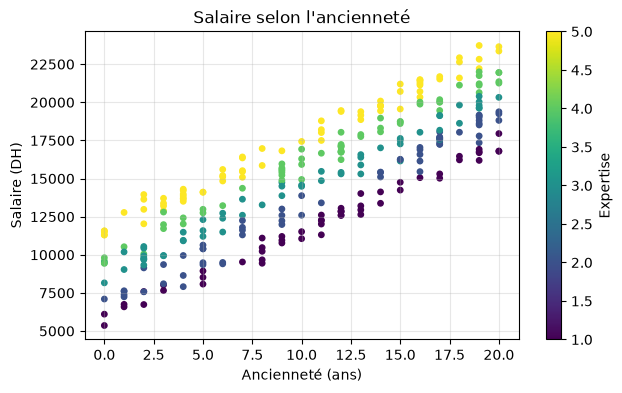

In [4]:
# Salaire selon l'ancienneté, couleur = expertise
plt.figure(figsize=(7, 4))
sc = plt.scatter(X[:, 0], y[:, 0], c=X[:, 1], cmap="viridis", s=15)
plt.colorbar(sc, label="Expertise")
plt.xlabel("Ancienneté (ans)")
plt.ylabel("Salaire (DH)")
plt.title("Salaire selon l'ancienneté")
plt.grid(True, alpha=0.3)
plt.show()

## 2. Séparer et préparer les données

In [5]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000   # en milliers de DH
y_test = y[test_indices] / 1000

moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

## 3. Construire et entraîner le modèle

In [7]:
model = nn.Linear(2, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

historique = []
model.train()

for epoch in range(500):
    optimizer.zero_grad()
    predictions = model(X_train_norm)
    loss = criterion(predictions, y_train)
    loss.backward()
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1} | Perte : {loss.item():.4f}")

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


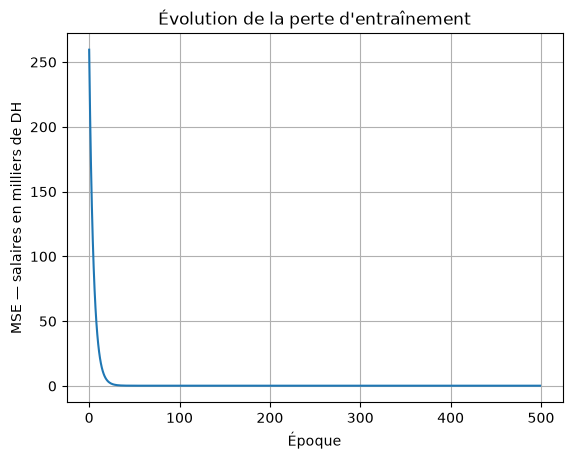

In [8]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

## 4. Évaluer les prédictions

In [9]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000
    mae = (predictions_dh - salaires_reels_dh).abs().mean()

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


## 5. Prédire le salaire d'un nouveau salarié (7 ans, expertise 4/5)

In [10]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")
print("Valeur théorique sans bruit : 4000 + 600*7 + 1500*4 = 14200 DH")

Salaire estimé : 14201.94 DH
Valeur théorique sans bruit : 4000 + 600*7 + 1500*4 = 14200 DH


### Retrouver les coefficients en unités d'origine

In [11]:
# Le modèle calcule : y/1000 = w * (x - moyenne)/ecart_type + b
# Donc en DH : coef = 1000 * w / ecart_type
w = model.weight.detach()[0]
b = model.bias.detach()[0]

coef = 1000 * w / ecart_type[0]
biais = 1000 * (b - (w * moyenne[0] / ecart_type[0]).sum())

print(f"Coef ancienneté : {coef[0].item():.1f}  (attendu ≈ 600)")
print(f"Coef expertise  : {coef[1].item():.1f}  (attendu ≈ 1500)")
print(f"Biais           : {biais.item():.1f}  (attendu ≈ 4000)")

Coef ancienneté : 592.7  (attendu ≈ 600)
Coef expertise  : 1490.7  (attendu ≈ 1500)
Biais           : 4090.3  (attendu ≈ 4000)


### Réponses aux questions

- **Effet d'une année d'ancienneté (expertise constante) :** le salaire augmente d'environ **600 DH** (le coefficient de l'ancienneté).
- **Pourquoi la perte n'est pas nulle :** à cause du **bruit** ajouté aux salaires (écart-type 500 DH). Le modèle ne peut pas prédire ce bruit aléatoire, donc il reste une erreur (MSE ≈ 0,25 en milliers² de DH).
- **40 ans d'ancienneté :** ce n'est **pas fiable**, c'est de l'extrapolation : les données vont seulement de 0 à 20 ans, on ne sait pas si la relation reste linéaire au-delà.
- **Plus de bruit :** la précision baisse (MAE plus grande) et les coefficients appris sont moins proches des vraies valeurs.
- **Coefficients :** voir la cellule précédente, ils sont proches de 600, 1500 et 4000.

---
# Exercice 2 : Classification — Iris

## 1. Préparation des données

In [12]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Réponses :**
- Les 4 colonnes : longueur des sépales, largeur des sépales, longueur des pétales, largeur des pétales (en cm).
- `torch.long` : `CrossEntropyLoss` attend des étiquettes **entières** (indices de classe 0, 1, 2), pas des flottants.
- On n'ajuste pas le scaler sur le test pour ne pas utiliser d'information du test pendant l'entraînement (**fuite de données**). Le test doit rester des données "jamais vues".

## 2. Construire le réseau

In [13]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

## 3. Entraîner le modèle

In [14]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    optimizer.zero_grad()
    logits = model(X_train)
    loss = criterion(logits, y_train)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


## 4. Évaluer le classifieur

In [15]:
model.eval()

with torch.no_grad():
    logits = model(X_test)
    predictions = logits.argmax(dim=1)
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


## 5. Autres questions

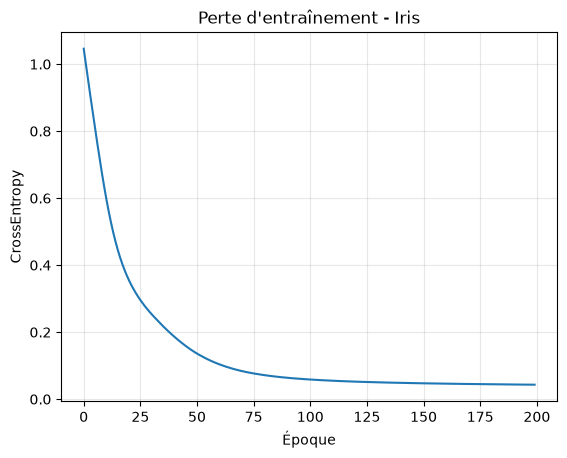

In [16]:
# Courbe de perte
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("CrossEntropy")
plt.title("Perte d'entraînement - Iris")
plt.grid(True, alpha=0.3)
plt.show()

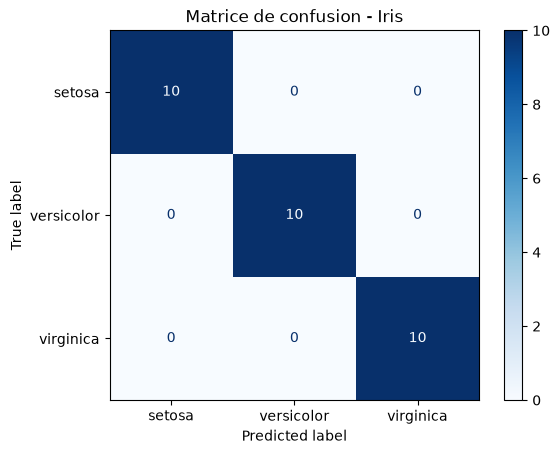

In [17]:
# Matrice de confusion
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(cmap="Blues")
plt.title("Matrice de confusion - Iris")
plt.show()

In [18]:
# Comparaison avec un modèle sans couche cachée
model_simple = nn.Linear(4, 3)
optimizer_simple = torch.optim.Adam(model_simple.parameters(), lr=0.01)

for epoch in range(200):
    optimizer_simple.zero_grad()
    loss = criterion(model_simple(X_train), y_train)
    loss.backward()
    optimizer_simple.step()

with torch.no_grad():
    acc_simple = (model_simple(X_test).argmax(dim=1) == y_test).float().mean()

print(f"Modèle avec couche cachée : {accuracy.item():.1%}")
print(f"Modèle sans couche cachée : {acc_simple.item():.1%}")

Modèle avec couche cachée : 100.0%
Modèle sans couche cachée : 90.0%


Iris est presque linéairement séparable : le modèle sans couche cachée marche déjà bien, mais la couche cachée (ReLU) aide un peu à mieux séparer versicolor et virginica.

In [19]:
# Prédiction d'une nouvelle fleur
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]
nouvelle_fleur = scaler.transform(nouvelle_fleur)
nouvelle_fleur = torch.tensor(nouvelle_fleur, dtype=torch.float32)

with torch.no_grad():
    classe = model(nouvelle_fleur).argmax(dim=1).item()

print("Espèce prédite :", iris.target_names[classe])

Espèce prédite : setosa


---
# Exercice 3 : MLP sur MNIST

## Chargement des données

In [20]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.82MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 266kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.44MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.38MB/s]


## Entraînement (5 époques)

In [21]:
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)

    print(f"Époque {epoch + 1}/{epochs} | Perte : {total_loss / len(train_dataset):.4f}")

Époque 1/5 | Perte : 0.3542
Époque 2/5 | Perte : 0.1667
Époque 3/5 | Perte : 0.1165
Époque 4/5 | Perte : 0.0888
Époque 5/5 | Perte : 0.0699


## Évaluation

In [22]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predicted_classes = outputs.argmax(dim=1)
        all_preds.append(predicted_classes)
        all_labels.append(labels)

all_preds = torch.cat(all_preds)
all_labels = torch.cat(all_labels)

In [23]:
# Métriques (moyenne "macro" car il y a 10 classes)
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

acc = accuracy_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds, average="macro")
prec = precision_score(all_labels, all_preds, average="macro")
f1 = f1_score(all_labels, all_preds, average="macro")

print(f"Accuracy = {acc:.4f}, Recall = {rec:.4f}, Precision = {prec:.4f}, F1-score = {f1:.4f}")

Accuracy = 0.9764, Recall = 0.9762, Precision = 0.9762, F1-score = 0.9762


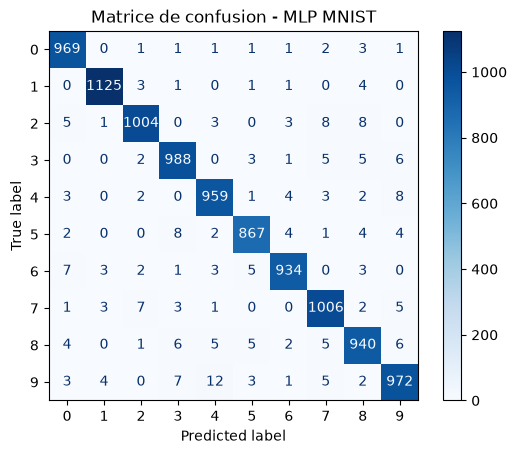

In [24]:
# Matrice de confusion
cm = confusion_matrix(all_labels, all_preds)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("Matrice de confusion - MLP MNIST")
plt.show()

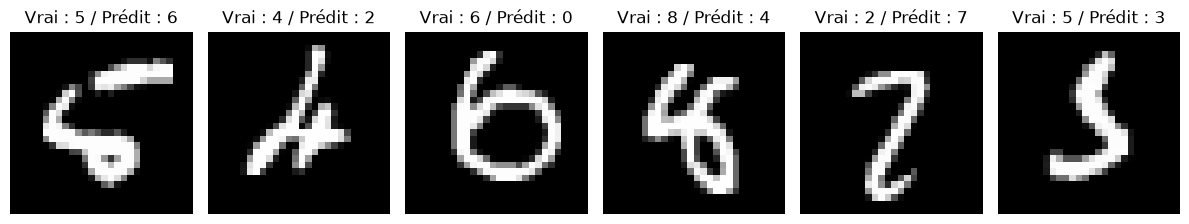

In [25]:
# Quelques images mal classées
erreurs = (all_preds != all_labels).nonzero().squeeze()

fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for ax, idx in zip(axes, erreurs[:6]):
    image, label = test_dataset[idx]
    ax.imshow(image[0], cmap="gray")
    ax.set_title(f"Vrai : {label} / Prédit : {all_preds[idx].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Sauvegarder et recharger le modèle

In [26]:
torch.save(model.state_dict(), "mnist_mlp.pth")

new_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
new_model.load_state_dict(torch.load("mnist_mlp.pth", weights_only=True))
new_model.eval()

images, labels = next(iter(test_loader))
with torch.no_grad():
    same = torch.equal(model(images).argmax(dim=1), new_model(images).argmax(dim=1))
print("Prédictions identiques après rechargement :", same)

Prédictions identiques après rechargement : True


---
# Exercice 4 : CNN sur MNIST

## 1. Chargement des données

In [27]:
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

images, labels = next(iter(train_loader))
print("Images :", images.shape)
print("Labels :", labels.shape)

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Réponses :**
- Les 4 dimensions `[64, 1, 28, 28]` : 64 images dans le batch, 1 canal (niveaux de gris), 28 pixels de hauteur, 28 pixels de largeur.
- `shuffle=True` : on mélange les données à chaque époque pour que le modèle ne voie pas toujours les images dans le même ordre, ce qui aide à mieux généraliser.

## 2. Visualiser quelques images

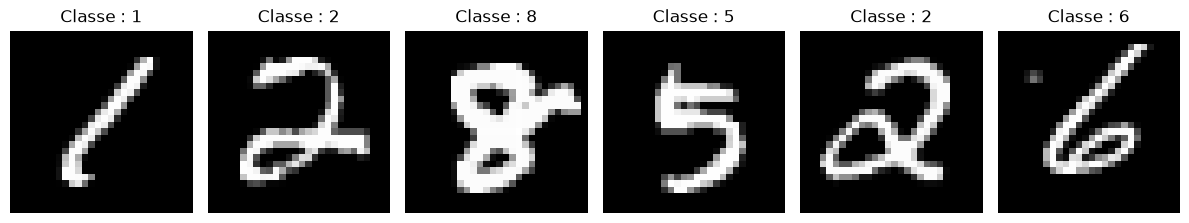

In [28]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    image = images[i, 0] * 0.3081 + 0.1307
    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Construire le CNN

In [29]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)

Sortie : torch.Size([64, 10])


**Pourquoi 32 × 7 × 7 ?**
Image 28×28 → (conv, padding=1 garde la taille) 28×28 → MaxPool 14×14 → conv 14×14 → MaxPool **7×7**.
La dernière convolution produit **32** cartes, donc 32 × 7 × 7 = 1568 valeurs après `Flatten`.

## 4. Entraîner le réseau

In [30]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

Époque 1/3 | Perte : 0.1679
Époque 2/3 | Perte : 0.0484
Époque 3/3 | Perte : 0.0348


## 5. Évaluer sur le jeu de test

In [31]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.89%


## Autres questions

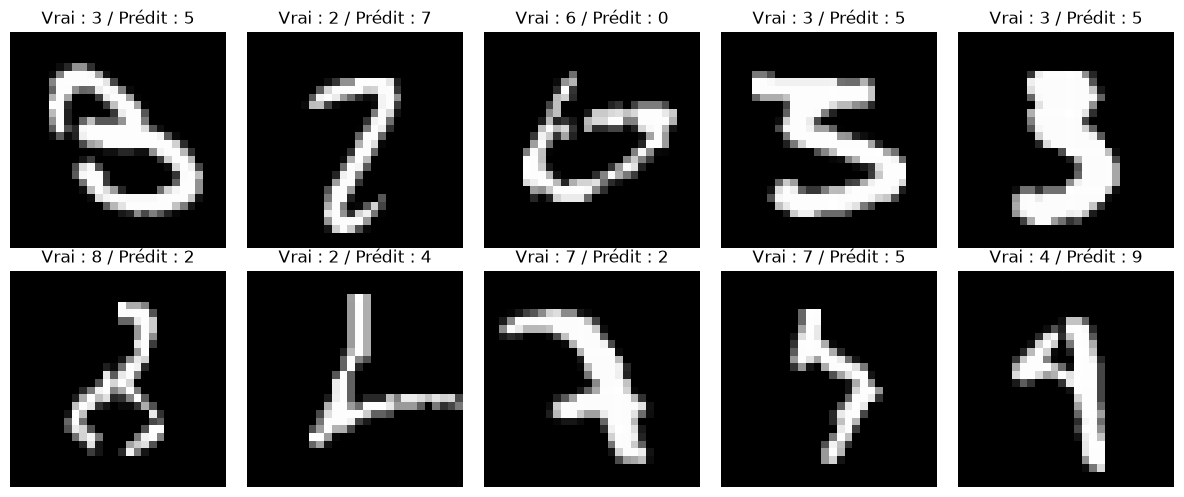

In [32]:
# 10 images mal classées
mal_classees = []

with torch.no_grad():
    for images, labels in test_loader:
        preds = model(images.to(device)).argmax(dim=1).cpu()
        for img, lab, p in zip(images, labels, preds):
            if lab != p:
                mal_classees.append((img, lab.item(), p.item()))
        if len(mal_classees) >= 10:
            break

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, (img, lab, p) in zip(axes.flatten(), mal_classees[:10]):
    ax.imshow(img[0] * 0.3081 + 0.1307, cmap="gray")
    ax.set_title(f"Vrai : {lab} / Prédit : {p}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [33]:
# CNN avec Dropout avant la dernière couche linéaire
class MNISTClassifierDropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model_drop = MNISTClassifierDropout().to(device)
optimizer = torch.optim.Adam(model_drop.parameters(), lr=0.001)

for epoch in range(3):
    model_drop.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model_drop(images), labels)
        loss.backward()
        optimizer.step()

model_drop.eval()
correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        preds = model_drop(images.to(device)).argmax(dim=1)
        correct += (preds == labels.to(device)).sum().item()

print(f"Accuracy avec Dropout : {correct / len(test_dataset):.2%}")

Accuracy avec Dropout : 98.74%


In [34]:
# Sauvegarde des paramètres
torch.save(model.state_dict(), "mnist_cnn.pth")
print("Modèle sauvegardé dans mnist_cnn.pth")

Modèle sauvegardé dans mnist_cnn.pth


---
# Conclusion

- **Exercice 1 :** un simple `nn.Linear(2, 1)` retrouve bien la relation du salaire (coefficients ≈ 600 et 1500).
- **Exercice 2 :** un petit MLP classe très bien les fleurs Iris.
- **Exercice 3 :** un MLP sur MNIST atteint environ 97 % d'accuracy.
- **Exercice 4 :** le CNN fait mieux (environ 98–99 %) car les convolutions exploitent la structure spatiale des images.